**Why Visualization Is Essential in the ML Workflow**
- it is not about creating pretty charts
- it is a computational and intuitive tools for understanding data structures, uncovering hidden patterns, and interpretting model behavior.

**The ML visualization Pipeline**

*things we have gone through and will go through include:*

*phase 1*
- Exploratory Data Analysis and Preprocessing

*phase 2*
- Feature Engineering

*phase 3*
- confusion Matrices
- Bias vs Variance
- Decision Boundaries

**The python Visualization Toolkit**
- Matplotlib: Low level visualization library
- Seaborn: High Level Visualization Library
- pandas & Numpy

In [ ]:
# Import our Basic Toolkit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Our dataset of interest
pd.set_option('display.max_columns', None)
try:
    us_edu_data = pd.read_csv('us_education_system_dataset.csv')
except FileNotFoundError:
    us_edu_data = pd.read_csv('/content/drive/MyDrive/second semester project/us_education_system_dataset.csv')
us_edu_data.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


In [ ]:
# Look at the Column Names
us_edu_data.columns

Index(['institution_id', 'institution_name', 'state_code', 'state_name',
       'county', 'nces_locale', 'level', 'control', 'title_i_status',
       'total_enrollment', 'number_of_teachers', 'student_teacher_ratio',
       'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct',
       'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct',
       'racial_two_or_more_pct', 'special_education_pct',
       'english_learner_pct', 'per_pupil_expenditure_usd',
       'federal_funding_pct', 'state_funding_pct', 'local_funding_pct',
       'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score',
       'avg_act_score', 'ap_ib_participation_pct',
       'postsecondary_enrollment_pct', 'stem_certified_flag',
       'broadband_access_pct'],
      dtype='object')

In [ ]:
# key matric across academic institutions
# Institutional Context:level, control, title atatus, location
# Resourses and Expenditure: Total enrollment, student-teacher ratio, pupil per expenditure, broadband access
# Demographics & Needs: Percent_free_reduced_lunch, special_education_pct, english_learner_pct
# Academic Outcomes: Math_proficiency_pct, Graduation_rate_pct,avg_sat_score,avg_act_score, postsecondary_enrollment_pct

In [ ]:
# Key Matrics Dataframe
us_edu_keymetrics_data = us_edu_data[['institution_name', 'level', 'control', 'per_pupil_expenditure_usd', 'percent_free_reduced_lunch', 'math_proficiency_pct', 'graduation_rate_pct']]
us_edu_keymetrics_data.head()

,institution_name,level,control,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct,graduation_rate_pct
0,Jefferson Elementary School,Elementary School,Public,12840,48.9,58.3,80.9
1,Lakeshore Middle School,Middle School,Private Religious,17009,1.2,84.8,93.5
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,15374,36.0,54.6,80.2
3,Roosevelt Primary School,Elementary School,Public,17065,15.1,66.1,82.1
4,Highland Park Primary School,Elementary School,Public,16823,45.6,54.6,90.2


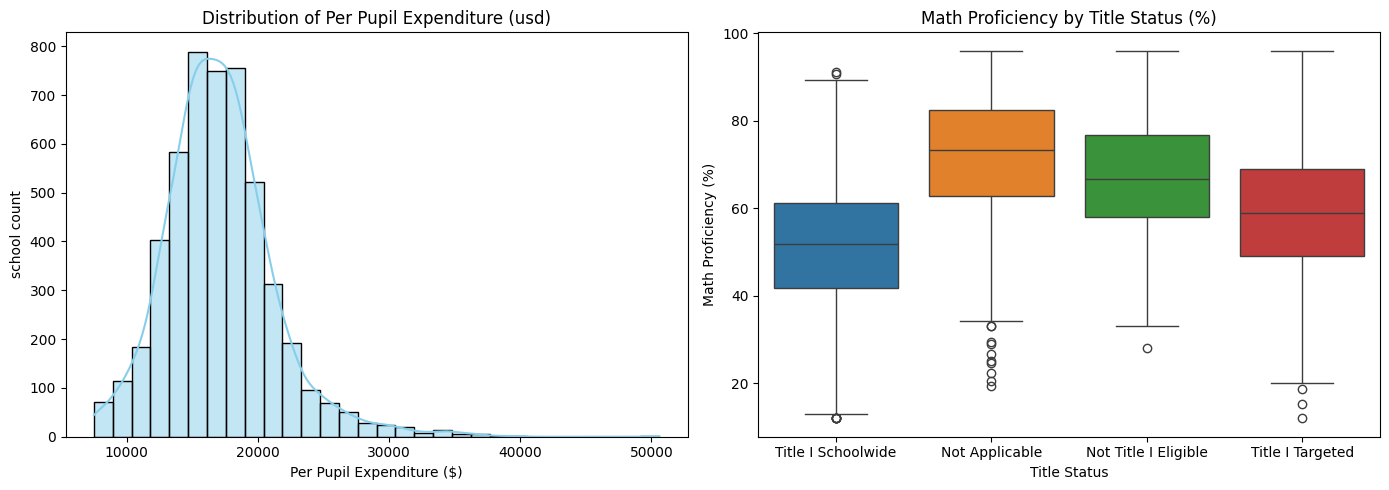

In [ ]:
# Univeraite Analysis - Inspect Distribution & Skewness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# plot- Histograme: Distribution Expenditure(per_pupil_Expenditure_usd)
sns.histplot(us_edu_keymetrics_data['per_pupil_expenditure_usd'], kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Distribution of Per Pupil Expenditure (usd)')
axes[0].set_xlabel('Per Pupil Expenditure ($)')
axes[0].set_ylabel('school count')

#plot 2- Mathe proficiency across title status
sns.boxplot(data=us_edu_data, x='title_i_status', y='math_proficiency_pct', hue='title_i_status', ax=axes[1])
axes[1].set_title('Math Proficiency by Title Status (%)')
axes[1].set_xlabel('Title Status')
axes[1].set_ylabel('Math Proficiency (%)')

plt.tight_layout()
plt.show()

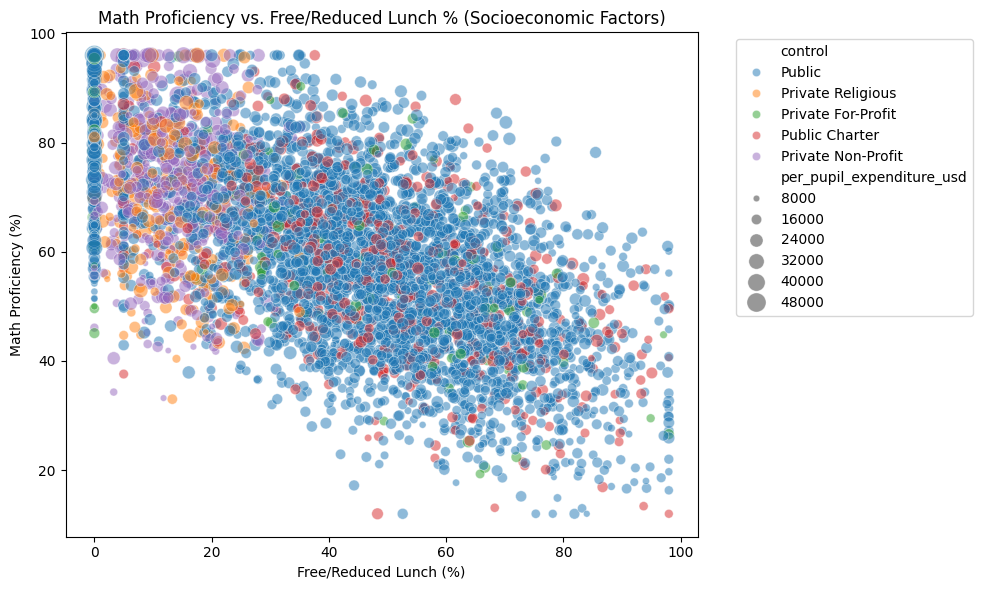

In [ ]:
# Bivariate & amp ; multivirate Analysis - uncovering Feature interactions
# faceted scatter plot wih color & size mapping
plt.figure(figsize=(10, 6))

sns.scatterplot(data=us_edu_keymetrics_data, x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='control', size='per_pupil_expenditure_usd',
                sizes=(20, 200) ,
                alpha=0.5 )

plt.title('Math Proficiency vs. Free/Reduced Lunch % (Socioeconomic Factors)')
plt.xlabel('Free/Reduced Lunch (%)')
plt.ylabel('Math Proficiency (%)')
plt.legend(bbox_to_anchor= (1.05, 1), loc ='upper left')
plt.tight_layout()
plt.show()

**Correlation Matrix & Heatmaps
- Heatmaps summarize Linear Relationships across numerical values

- Identifies redundant features

In [ ]:
# Check the Data Info
us_edu_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   institution_id                5000 non-null   object 
 1   institution_name              5000 non-null   object 
 2   state_code                    5000 non-null   object 
 3   state_name                    5000 non-null   object 
 4   county                        5000 non-null   object 
 5   nces_locale                   5000 non-null   object 
 6   level                         5000 non-null   object 
 7   control                       5000 non-null   object 
 8   title_i_status                5000 non-null   object 
 9   total_enrollment              5000 non-null   int64  
 10  number_of_teachers            5000 non-null   int64  
 11  student_teacher_ratio         5000 non-null   float64
 12  percent_free_reduced_lunch    5000 non-null   float64
 13  rac

In [ ]:
# continous Numeric Performance Indicators
numeric_cols = ['per_pupil_expenditure_usd','student_teacher_ratio',
                'percent_free_reduced_lunch','special_education_pct',
                'english_learner_pct','math_proficiency_pct','reading_proficiency_pct'
                ,'graduation_rate_pct','chronic_absenteeism_pct'
                ]

In [ ]:
#correlation Matrix
corr_matrix= us_edu_data[numeric_cols].corr()

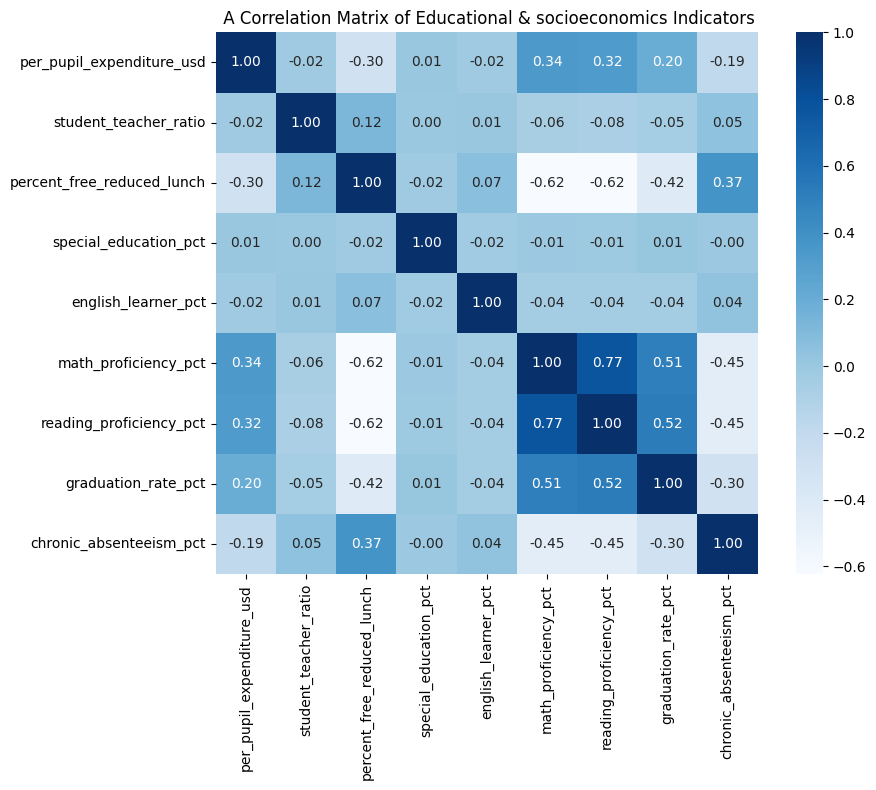

In [ ]:
# HeatMap and Feature selection
plt.figure(figsize=(10, 8))
# draw the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='Blues',square= True, fmt=".2f", cbar=True)
plt.title(' A Correlation Matrix of Educational & socioeconomics Indicators')
plt.tight_layout()
plt.show()

**Model Diagnostic**
- Model Performance Evaluation

In [ ]:
from sklearn.model_selection import train_test_split # split our training/test Data
from sklearn.ensemble import RandomForestClassifier # ML Algorithm
from sklearn.metrics import confusion_matrix # Performance Evaluator

In [ ]:
# clean Data
data_clean = us_edu_data[numeric_cols].dropna()

In [ ]:
X = data_clean.drop(columns =['math_proficiency_pct'])
y = (data_clean['math_proficiency_pct'] >= data_clean['math_proficiency_pct'].median()).astype(int)

In [ ]:
X.head()

,per_pupil_expenditure_usd,student_teacher_ratio,percent_free_reduced_lunch,special_education_pct,english_learner_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct
0,12840,14.8,48.9,14.4,12.9,58.1,80.9,18.0
1,17009,10.0,1.2,13.7,19.3,98.0,93.5,17.8
2,15374,18.2,36.0,15.7,11.3,66.2,80.2,19.5
3,17065,11.3,15.1,13.8,9.8,70.5,82.1,20.5
4,16823,13.9,45.6,19.8,5.3,46.7,90.2,19.9


In [ ]:
y.head()

,math_proficiency_pct
0,0
1,1
2,0
3,1
4,0


In [ ]:
# split our training and test data
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# train our model
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

In [ ]:
# compute & plot the confusion Matrix
cm = confusion_matrix(y_test, y_pred)

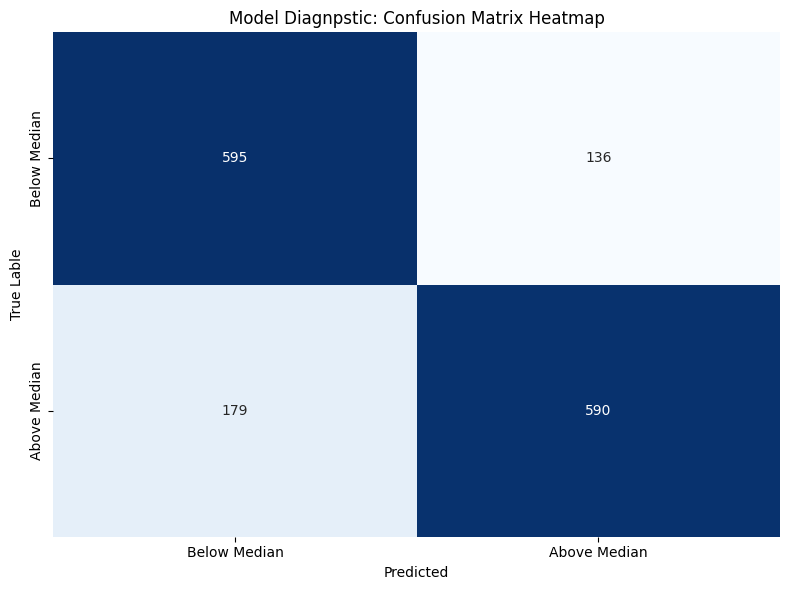

In [ ]:
# visualize our performance
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Below Median', 'Above Median'],
            yticklabels=['Below Median', 'Above Median'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True Lable')
plt.title('Model Diagnpstic: Confusion Matrix Heatmap')
plt.tight_layout()
plt.show()

**Dimensionality Reduction**

- capture variance

In [ ]:
# import our unsupervised ML modules
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
# standardized our feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# apply PCA projection to 2 Dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

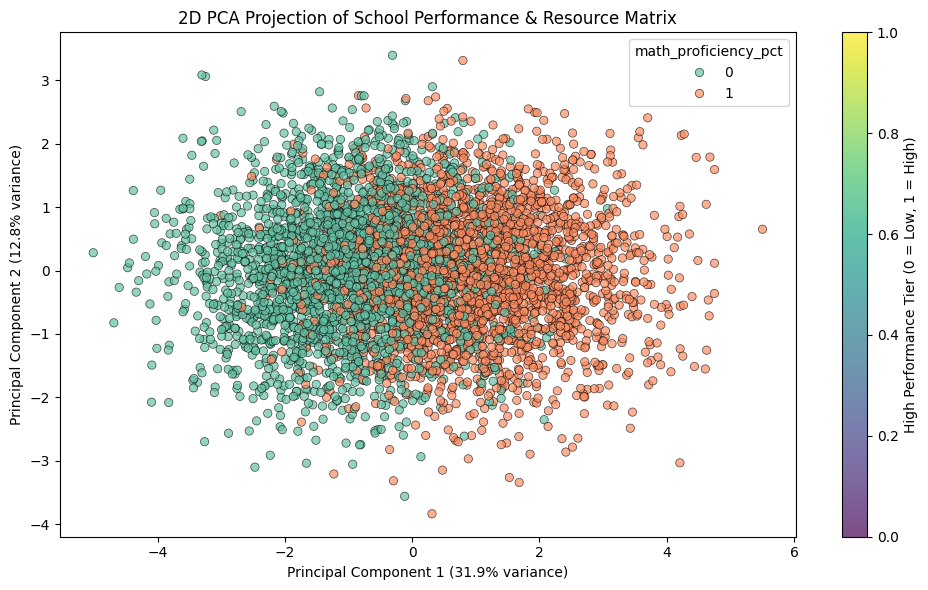

In [ ]:
# visualize our 2D PCA Embeddings
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Set2', alpha=0.7,
                          edgecolors='k', linewidth=0.5)

# Retrieve the path collections to create the colorbar safely
points = scatter.collections[0]
plt.colorbar(points, label='High Performance Tier (0 = Low, 1 = High)')

plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)')
plt.title('2D PCA Projection of School Performance & Resource Matrix')
plt.tight_layout()
plt.show()